In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Библиотеки загружены!")

Библиотеки загружены!


In [2]:
df = pd.read_csv("../data/Auto.csv")

print("Размер датасета:", df.shape)

print("\nНазвания столбцов:")
print(df.columns.tolist())

print("\nПервые 5 строк:")
df.head()

Размер датасета: (392, 9)

Названия столбцов:
['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'year', 'origin', 'name']

Первые 5 строк:


,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [3]:
# Проверяем типы данных
print("Типы данных:")
print(df.dtypes)

# Проверяем пропущенные значения
print("\nПропущенные значения:")
print(df.isnull().sum())

# Проверяем строки-дубликаты
print("\nКоличество дубликатов:", df.duplicated().sum())

# Проверяем статистику числовых признаков
print("\nОсновная статистика:")
df.describe()

Типы данных:
mpg             float64
cylinders         int64
displacement    float64
horsepower        int64
weight            int64
acceleration    float64
year              int64
origin            int64
name                str
dtype: object

Пропущенные значения:
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
year            0
origin          0
name            0
dtype: int64

Количество дубликатов: 0

Основная статистика:


,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin
count,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000
mean,23.445918,5.471939,194.411990,104.469388,2977.584184,15.541327,75.979592,1.576531
std,7.805007,1.705783,104.644004,38.491160,849.402560,2.758864,3.683737,0.805518
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.000000,4.000000,105.000000,75.000000,2225.250000,13.775000,73.000000,1.000000
50%,22.750000,4.000000,151.000000,93.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,275.750000,126.000000,3614.750000,17.025000,79.000000,2.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000,3.000000


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Целевая переменная — mpg
X = df.drop(columns=["mpg", "name"])
y = df["mpg"]

# Делим данные на обучающую и тестовую части
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Создаём пайплайн предобработки и модели
baseline_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regression", LinearRegression())
])

# Обучаем модель
baseline_model.fit(X_train, y_train)

# Делаем предсказания
y_pred_baseline = baseline_model.predict(X_test)

# Оцениваем качество
mae_baseline = mean_absolute_error(y_test, y_pred_baseline)
rmse_baseline = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
r2_baseline = r2_score(y_test, y_pred_baseline)

print("Базовая модель")
print("MAE:", round(mae_baseline, 3))
print("RMSE:", round(rmse_baseline, 3))
print("R²:", round(r2_baseline, 3))

Базовая модель
MAE: 2.42
RMSE: 3.273
R²: 0.79


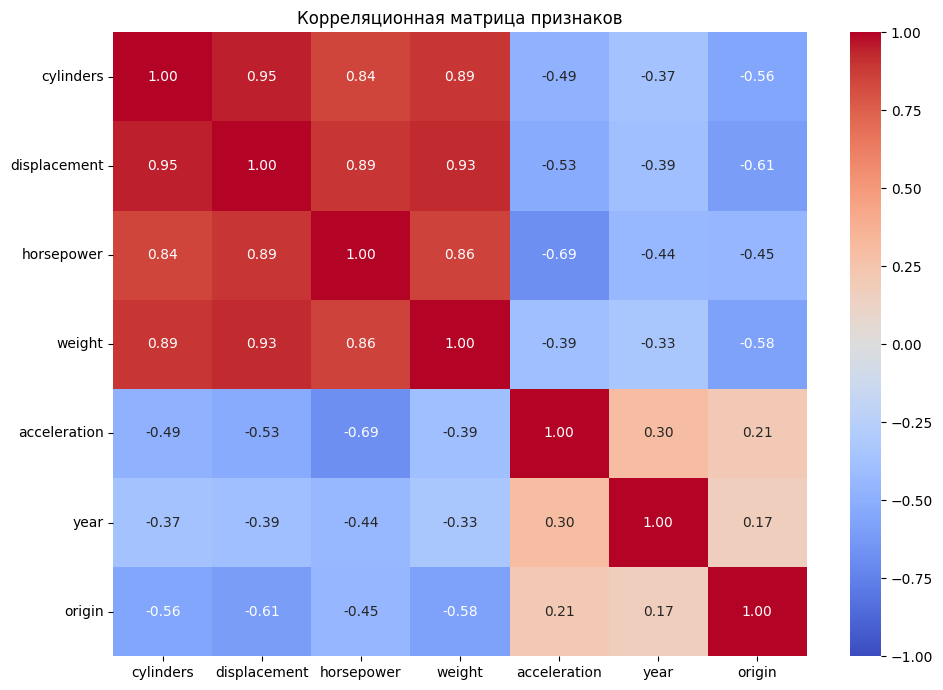

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

# Строим корреляционную матрицу
correlation_matrix = X_train.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Корреляционная матрица признаков")
plt.tight_layout()
plt.show()

In [6]:
# Выбираем признаки с меньшей взаимной корреляцией
reduced_features = [
    "horsepower",
    "weight",
    "acceleration",
    "year",
    "origin"
]

# Оставляем только выбранные признаки
X_train_reduced = X_train[reduced_features]
X_test_reduced = X_test[reduced_features]

# Создаём модель с тем же пайплайном
reduced_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regression", LinearRegression())
])

# Обучаем модель
reduced_model.fit(X_train_reduced, y_train)

# Делаем предсказания
y_pred_reduced = reduced_model.predict(X_test_reduced)

# Считаем метрики качества
mae_reduced = mean_absolute_error(y_test, y_pred_reduced)
rmse_reduced = np.sqrt(mean_squared_error(y_test, y_pred_reduced))
r2_reduced = r2_score(y_test, y_pred_reduced)

print("Модель с уменьшенным количеством признаков")
print("MAE:", round(mae_reduced, 3))
print("RMSE:", round(rmse_reduced, 3))
print("R²:", round(r2_reduced, 3))

Модель с уменьшенным количеством признаков
MAE: 2.462
RMSE: 3.344
R²: 0.781


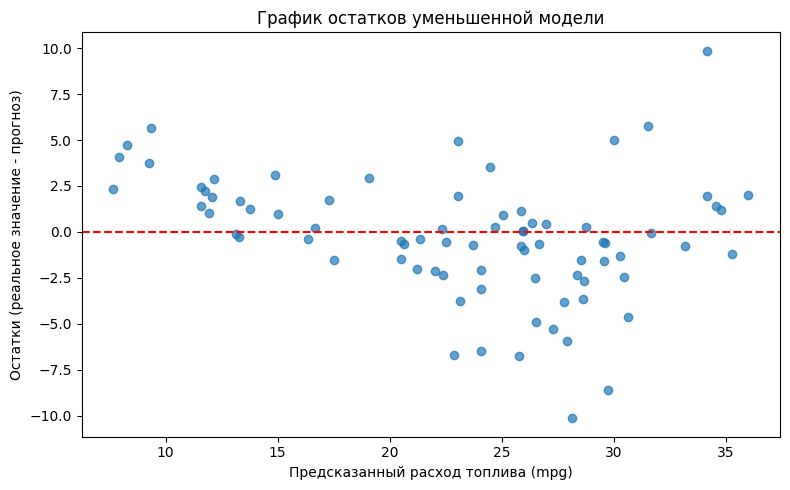

In [7]:
# Считаем остатки уменьшенной модели
residuals = y_test - y_pred_reduced

# Строим график остатков
plt.figure(figsize=(8, 5))
plt.scatter(y_pred_reduced, residuals, alpha=0.7)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Предсказанный расход топлива (mpg)")
plt.ylabel("Остатки (реальное значение - прогноз)")
plt.title("График остатков уменьшенной модели")
plt.tight_layout()
plt.show()

### Анализ графика остатков

На графике остатки распределены вокруг нулевой линии, но не полностью равномерно. Наблюдаются отдельные большие ошибки, достигающие примерно −10 и +10 mpg. Это говорит о том, что модель не всегда точно предсказывает расход топлива и может не учитывать некоторые зависимости между признаками и целевой переменной. Следовательно, линейная модель подходит для приблизительного прогноза, но её качество можно улучшить.